In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [3]:
train= pd.read_excel(r"C:\Users\keert\OneDrive\Desktop\AUC CASE STUDY\Financial_Product_train.xlsx")
test=pd.read_excel(r"C:\Users\keert\OneDrive\Desktop\AUC CASE STUDY\Financial_Product_test.xlsx")
validation=pd.read_excel(r"C:\Users\keert\OneDrive\Desktop\AUC CASE STUDY\Financial_Product_Validation.xlsx")

In [4]:
train.shape

(40508, 16)

In [5]:
train.count()

CustomerAge                40508
Occupation                 40508
MaritalStatus              40508
EducationLevel             40508
MultipleConnections        40508
AccountBalance             40508
HasLandline                40508
HasSmartphone              40508
LastContactDay             40508
LastContactMonth           40508
LastContactDuration        40508
TotalCampaignContacts      40508
DaysSinceLastContact       40508
PreviousContacts           40508
PreviousCampaignOutcome    40508
SubscribedProduct          40508
dtype: int64

In [6]:
train.head()

,CustomerAge,Occupation,MaritalStatus,EducationLevel,MultipleConnections,AccountBalance,HasLandline,HasSmartphone,LastContactDay,LastContactMonth,LastContactDuration,TotalCampaignContacts,DaysSinceLastContact,PreviousContacts,PreviousCampaignOutcome,SubscribedProduct
0,18,student,single,High School,no,608,no,no,13,nov,210,1,93,1,success,Yes
1,18,student,single,Other,no,35,no,no,21,aug,104,2,-1,0,unknown,No
2,18,student,single,Other,no,438,no,no,1,sep,425,1,-1,0,unknown,No
3,18,student,single,Other,no,108,no,no,10,aug,167,1,-1,0,unknown,Yes
4,18,student,single,High School,no,1944,no,no,10,aug,122,3,-1,0,unknown,No


In [7]:
train.isnull().sum()

CustomerAge                0
Occupation                 0
MaritalStatus              0
EducationLevel             0
MultipleConnections        0
AccountBalance             0
HasLandline                0
HasSmartphone              0
LastContactDay             0
LastContactMonth           0
LastContactDuration        0
TotalCampaignContacts      0
DaysSinceLastContact       0
PreviousContacts           0
PreviousCampaignOutcome    0
SubscribedProduct          0
dtype: int64

In [8]:
train.describe()

,CustomerAge,AccountBalance,LastContactDay,LastContactDuration,TotalCampaignContacts,DaysSinceLastContact,PreviousContacts
count,40508.000000,40508.000000,40508.000000,40508.000000,40508.000000,40508.000000,40508.000000
mean,40.969488,1372.520514,15.818826,257.401229,2.768243,40.218475,0.581144
std,10.633359,3088.652335,8.321429,255.378762,3.092290,100.061376,2.333588
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,73.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,450.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1436.250000,21.000000,318.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,58.000000,871.000000,275.000000


In [9]:
train['SubscribedProduct'] = train ['SubscribedProduct'].map({'Yes':1, 'No': 0 , 'yes': 1, 'no':0})
validation['SubscribedProduct'] = validation ['SubscribedProduct'].map({'Yes':1, 'No': 0 , 'yes': 1, 'no':0})
test['SubscribedProduct'] = test ['SubscribedProduct'].map({'Yes':1, 'No': 0 , 'yes': 1, 'no':0})

#YES 1 and NO is 0

In [13]:
train.shape

(40508, 16)

In [14]:
test.shape

(4562, 16)

In [15]:
validation.shape

(4521, 16)

C:\Users\keert\AppData\Local\Temp\ipykernel_17148\2775822888.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='SubscribedProduct', data=train, palette='viridis')


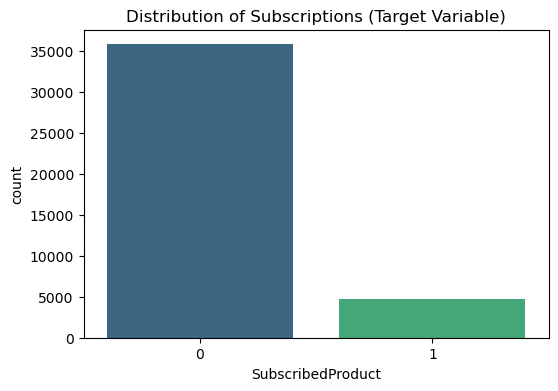

In [16]:
plt.figure(figsize=(6, 4))
sns.countplot(x='SubscribedProduct', data=train, palette='viridis')
plt.title('Distribution of Subscriptions (Target Variable)')
plt.show()

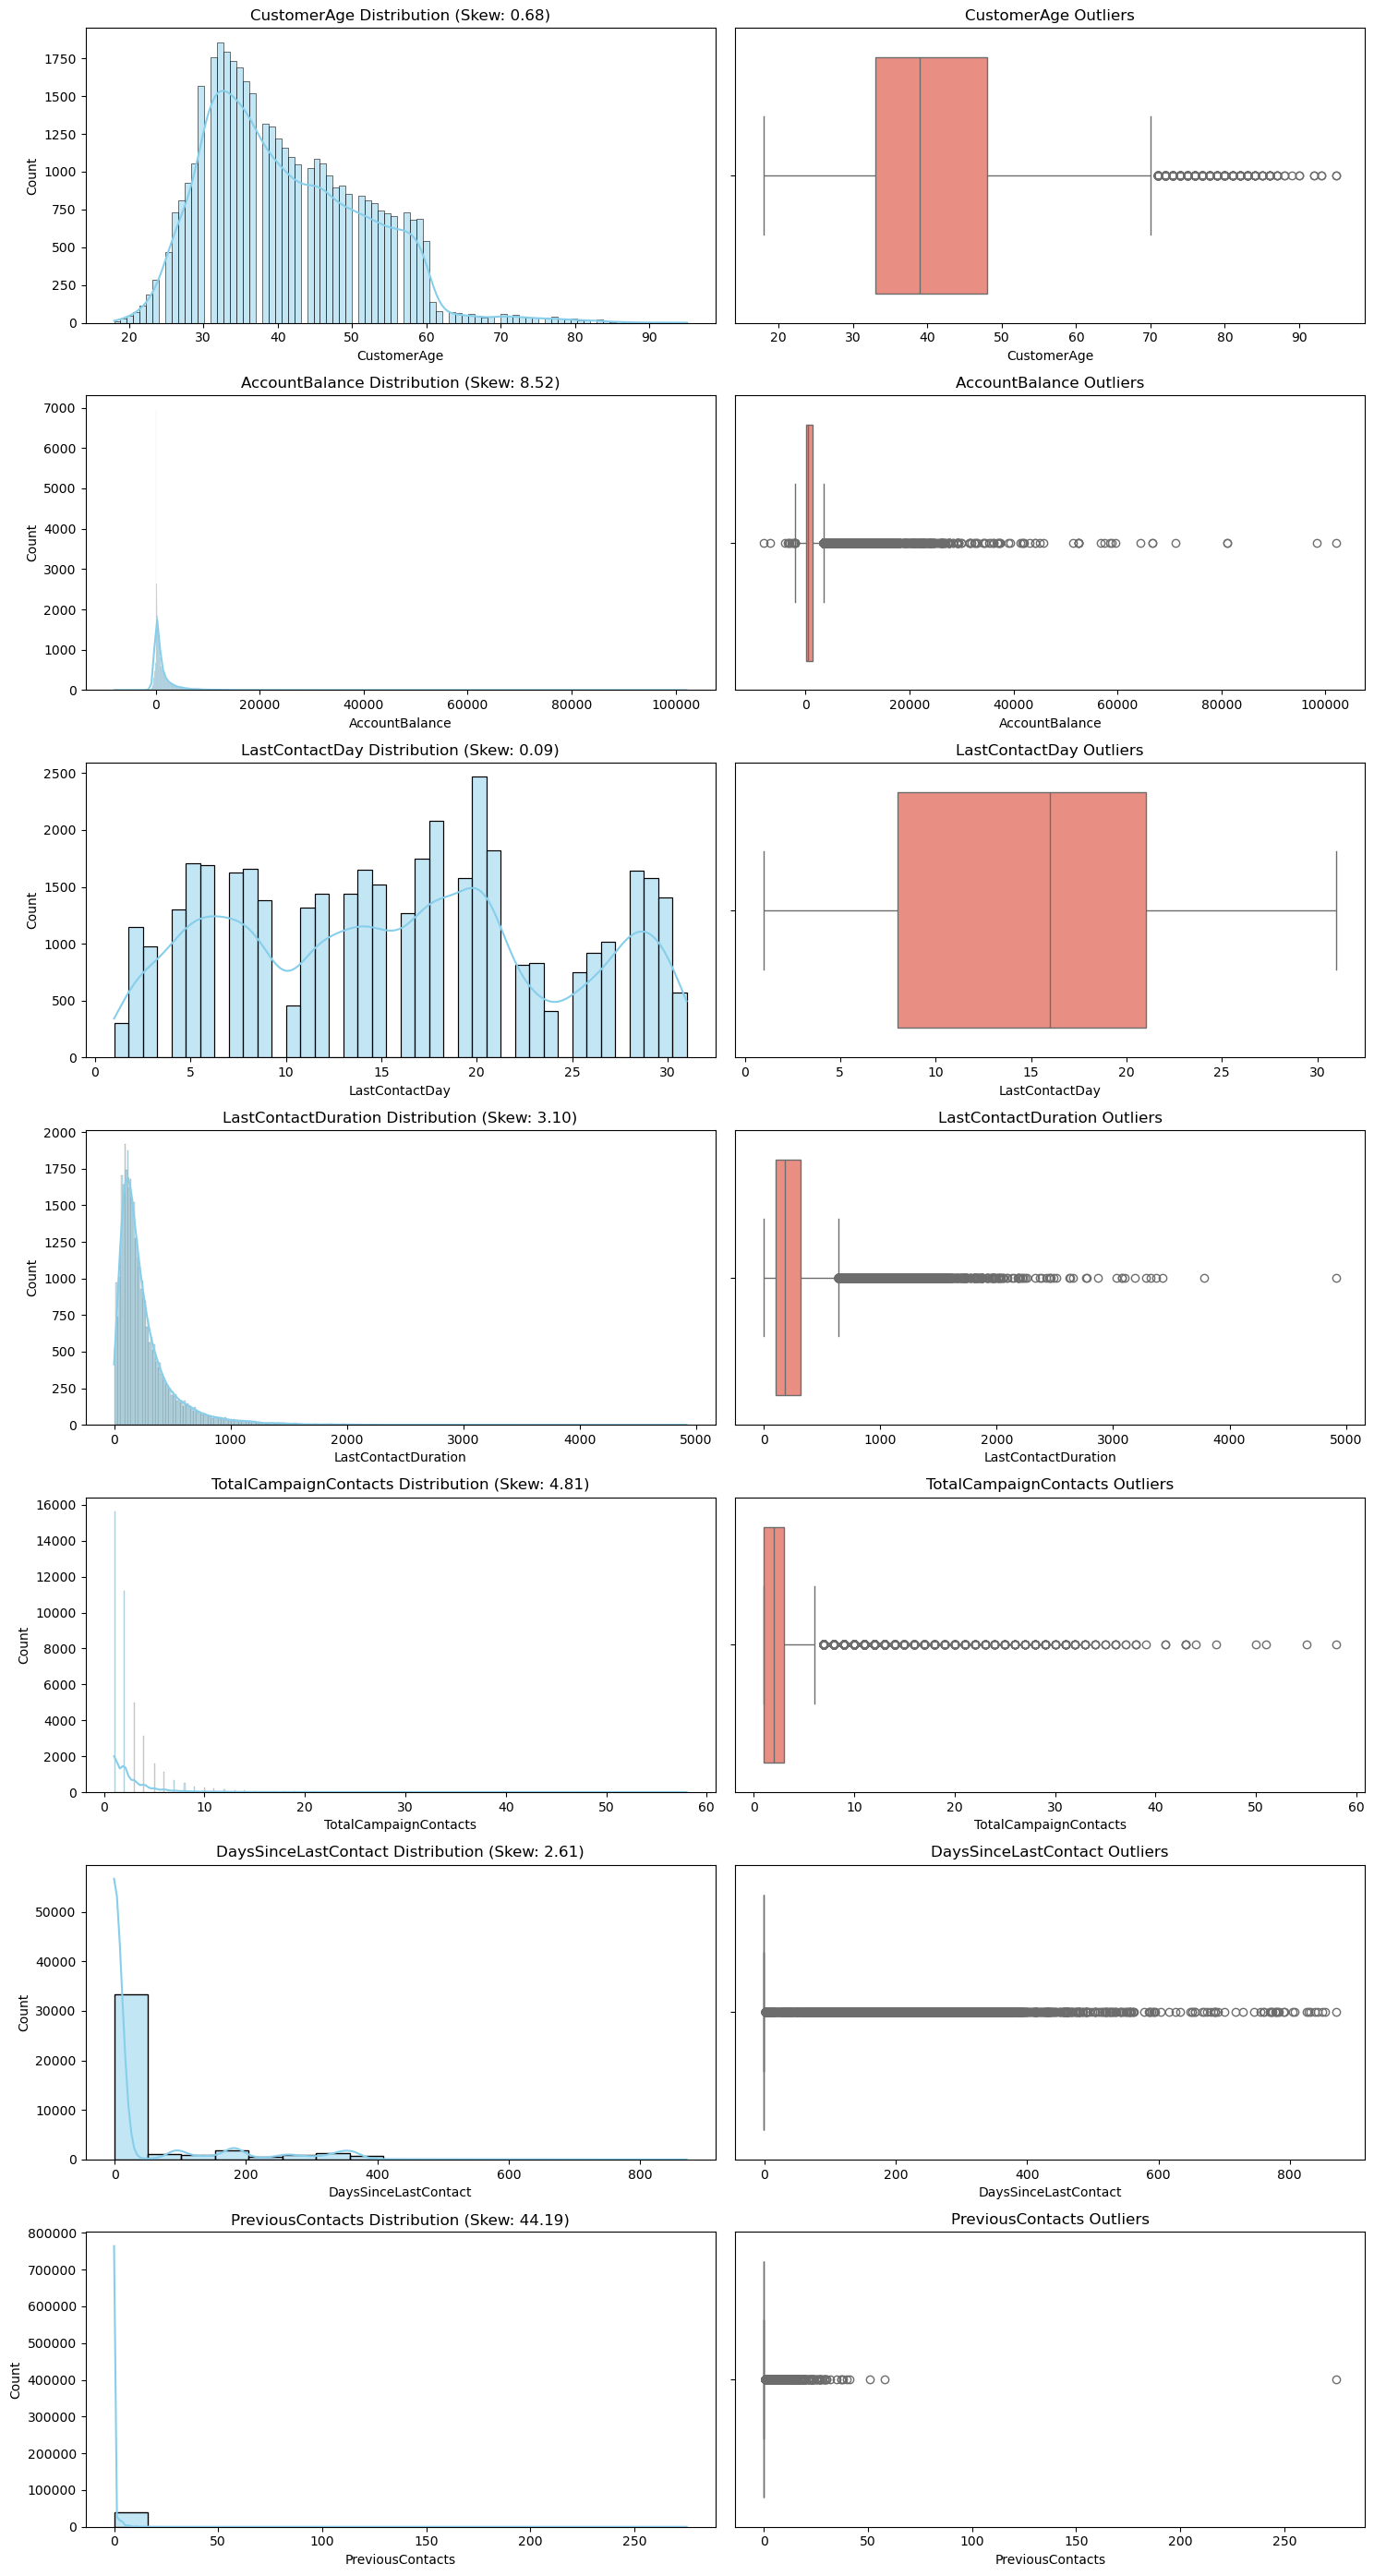

                            skew     kurtosis          std         mean  \
CustomerAge             0.679266     0.300789    10.633359    40.969488   
AccountBalance          8.521263   144.962946  3088.652335  1372.520514   
LastContactDay          0.089555    -1.058124     8.321429    15.818826   
LastContactDuration     3.102075    17.640001   255.378762   257.401229   
TotalCampaignContacts   4.810385    36.892907     3.092290     2.768243   
DaysSinceLastContact    2.611121     6.895413   100.061376    40.218475   
PreviousContacts       44.189408  4764.144763     2.333588     0.581144   

                       median  
CustomerAge              39.0  
AccountBalance          450.0  
LastContactDay           16.0  
LastContactDuration     180.0  
TotalCampaignContacts     2.0  
DaysSinceLastContact     -1.0  
PreviousContacts          0.0  


In [17]:
# List of numerical columns
num_cols = [
    'CustomerAge', 'AccountBalance', 'LastContactDay', 
    'LastContactDuration', 'TotalCampaignContacts', 
    'DaysSinceLastContact', 'PreviousContacts'
]

# Set up the plotting area
fig, axes = plt.subplots(len(num_cols), 2, figsize=(15, 4 * len(num_cols)))

for i, col in enumerate(num_cols):
    # 1. Distribution & Skewness Plot
    sns.histplot(train[col], kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'{col} Distribution (Skew: {train[col].skew():.2f})')
    
    # 2. Outlier Detection Plot
    sns.boxplot(x=train[col], ax=axes[i, 1], color='salmon')
    axes[i, 1].set_title(f'{col} Outliers')

plt.tight_layout()
plt.show()

# Quick summary statistics for Skewness and Kurtosis
print(train[num_cols].agg(['skew', 'kurtosis', 'std', 'mean', 'median']).transpose())

C:\Users\keert\AppData\Local\Temp\ipykernel_17148\2247183124.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_stats = train.groupby('AgeGroup')['SubscribedProduct'].value_counts(normalize=True).unstack() * 100


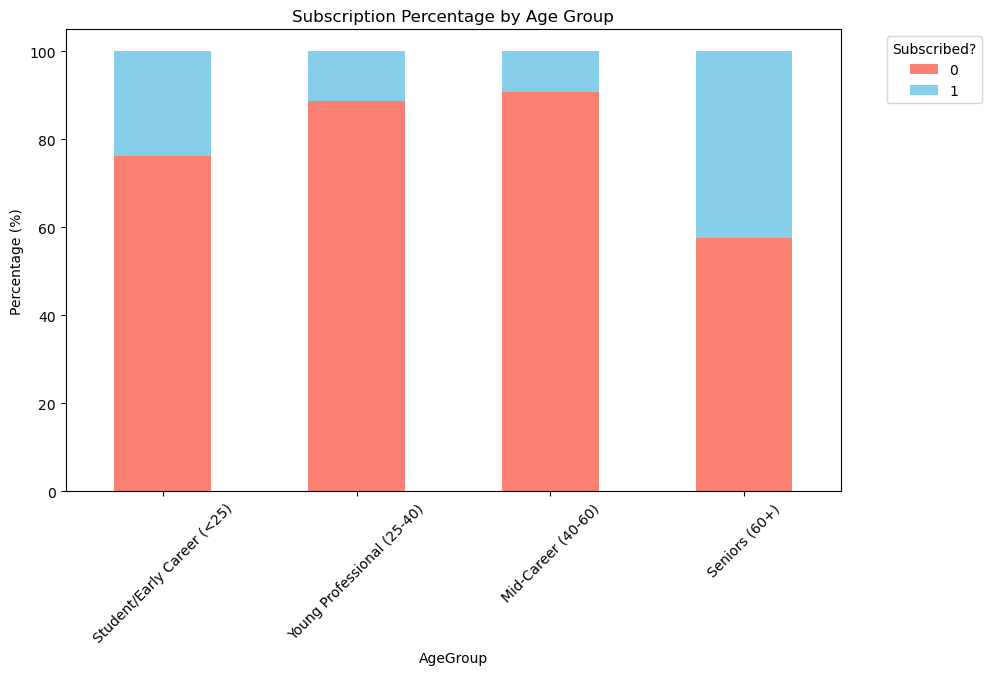

SubscribedProduct                   0          1
AgeGroup                                        
Student/Early Career (<25)  76.162791  23.837209
Young Professional (25-40)  88.825023  11.174977
Mid-Career (40-60)          90.681189   9.318811
Seniors (60+)               57.581395  42.418605


In [18]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Create Age Bins
train['AgeGroup'] = pd.cut(train['CustomerAge'], bins=[0, 25, 40, 60, 100], 
                        labels=['Student/Early Career (<25)', 'Young Professional (25-40)', 
                                'Mid-Career (40-60)', 'Seniors (60+)'])

# 2. Calculate Subscription Rate per Age Group
age_stats = train.groupby('AgeGroup')['SubscribedProduct'].value_counts(normalize=True).unstack() * 100

# 3. Plotting
age_stats.plot(kind='bar', stacked=True, figsize=(10,6), color=['salmon', 'skyblue'])
plt.title('Subscription Percentage by Age Group')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45)
plt.legend(title='Subscribed?', bbox_to_anchor=(1.05, 1))
plt.show()

print(age_stats)

# seniors and early career students  has subcribed  more compare too young professional and mid career

C:\Users\keert\AppData\Local\Temp\ipykernel_17148\3948858533.py:2: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(train[train['SubscribedProduct'] == 1]['LastContactDuration'], label='Subscribed', shade=True)
C:\Users\keert\AppData\Local\Temp\ipykernel_17148\3948858533.py:3: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(train[train['SubscribedProduct'] == 0]['LastContactDuration'], label='Not Subscribed', shade=True)


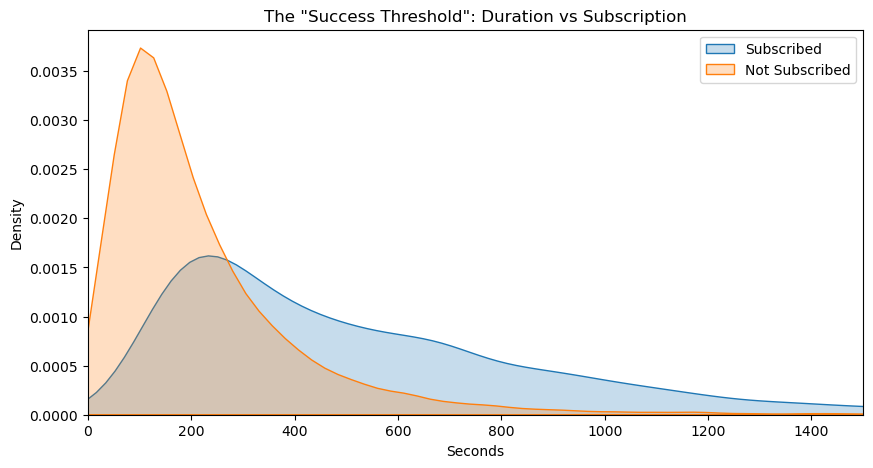

In [19]:
plt.figure(figsize=(10, 5))
sns.kdeplot(train[train['SubscribedProduct'] == 1]['LastContactDuration'], label='Subscribed', shade=True)
sns.kdeplot(train[train['SubscribedProduct'] == 0]['LastContactDuration'], label='Not Subscribed', shade=True)
plt.xlim(0, 1500) # Cut off extreme outliers to see the bulk of the data
plt.title('The "Success Threshold": Duration vs Subscription')
plt.xlabel('Seconds')
plt.legend()
plt.show()

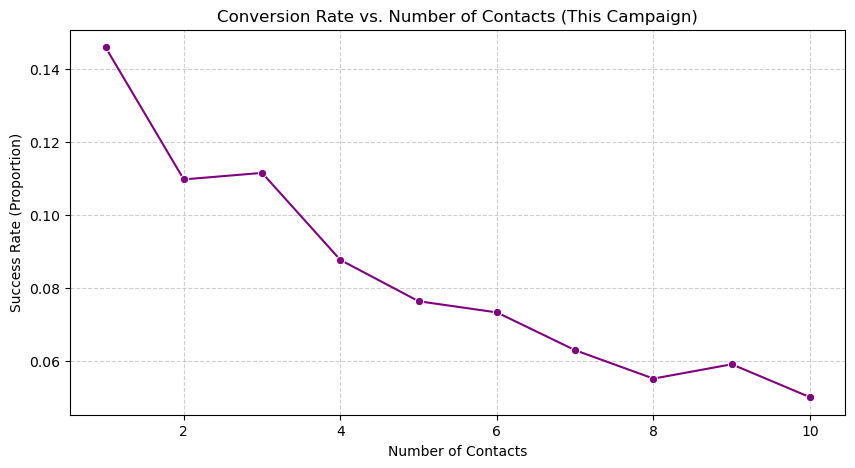

In [20]:
# Updated code:
campaign_stats = train[train['TotalCampaignContacts'] <= 10].groupby('TotalCampaignContacts')['SubscribedProduct'].mean()

plt.figure(figsize=(10, 5))
sns.lineplot(x=campaign_stats.index, y=campaign_stats.values, marker='o', color='purple')
plt.title('Conversion Rate vs. Number of Contacts (This Campaign)')
plt.xlabel('Number of Contacts')
plt.ylabel('Success Rate (Proportion)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [21]:
# List of binary columns to convert
binary_cols = ['MultipleConnections', 'HasLandline', 'HasSmartphone', ]

# Apply the mapping to all of them
for col in binary_cols:
    train[col] = train[col].map({'yes': 1, 'no': 0, 'Yes': 1, 'No': 0})
    test[col] = test[col].map({'yes': 1, 'no': 0, 'Yes': 1, 'No': 0})
    validation[col] = validation[col].map({'yes': 1, 'no': 0, 'Yes': 1, 'No': 0})

# Verify the change
print(train[['MultipleConnections', 'HasLandline', 'HasSmartphone', ]].head())
print(validation[['MultipleConnections', 'HasLandline', 'HasSmartphone', ]].head())
print(test[['MultipleConnections', 'HasLandline', 'HasSmartphone', ]].head())

   MultipleConnections  HasLandline  HasSmartphone
0                    0            0              0
1                    0            0              0
2                    0            0              0
3                    0            0              0
4                    0            0              0
   MultipleConnections  HasLandline  HasSmartphone
0                    0            1              1
1                    0            0              0
2                    0            1              0
3                    0            1              0
4                    0            0              1
   MultipleConnections  HasLandline  HasSmartphone
0                    0            1              0
1                    0            1              0
2                    0            0              0
3                    0            1              0
4                    0            0              0


In [22]:
train.shape

(40508, 17)

In [23]:
test.shape

(4562, 16)

In [25]:
validation.shape

(4521, 16)

In [27]:
# Apply the "Never Contacted" replacement to all dataframes
train['DaysSinceLastContact'] = train['DaysSinceLastContact'].replace(-1, 999)
validation['DaysSinceLastContact'] = validation['DaysSinceLastContact'].replace(-1, 999)
test['DaysSinceLastContact'] = test['DaysSinceLastContact'].replace(-1, 999)

# Verify for all three
print("Train -1s remaining:", (train['DaysSinceLastContact'] == -1).sum())
print("Validation -1s remaining:", (validation['DaysSinceLastContact'] == -1).sum())
print("Test -1s remaining:", (test['DaysSinceLastContact'] == -1).sum())

Train -1s remaining: 0
Validation -1s remaining: 0
Test -1s remaining: 0


In [29]:
# 1. Replace the values in PreviousContacts directly
# 1 if they were contacted before (>0), 0 otherwise
train['PreviousContacts'] = (train['PreviousContacts'] > 0).astype(int)
test['PreviousContacts'] = (test['PreviousContacts'] > 0).astype(int)
validation['PreviousContacts'] = (validation['PreviousContacts'] > 0).astype(int)

# 2. Drop LastContactDuration to prevent data leakage
# We do this 'in-place' to keep the dataframe lean
train.drop(columns=['LastContactDuration'], inplace=True)
test.drop(columns=['LastContactDuration'], inplace=True)
validation.drop(columns=['LastContactDuration'], inplace=True)



KeyError: "['LastContactDuration'] not found in axis"

In [33]:
test

,CustomerAge,Occupation,MaritalStatus,EducationLevel,MultipleConnections,AccountBalance,HasLandline,HasSmartphone,LastContactDay,LastContactMonth,TotalCampaignContacts,DaysSinceLastContact,PreviousContacts,PreviousCampaignOutcome,SubscribedProduct
0,32,freelance,married,Bachelor Degree,0,610,1,0,28,may,6,999,0,unknown,0
1,34,administration,married,Master Degree,0,520,1,0,12,aug,4,999,0,unknown,1
2,46,businessperson,married,Master Degree,0,1920,0,0,22,aug,6,999,0,unknown,1
3,29,laborer,single,Bachelor Degree,0,874,1,0,15,may,5,999,0,unknown,0
4,60,pensioned,married,High School,0,219,0,0,29,aug,2,999,0,unknown,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4557,32,laborer,single,Bachelor Degree,0,799,0,1,23,jul,6,999,0,unknown,1
4558,34,administration,married,Master Degree,0,0,1,0,21,may,2,999,0,unknown,0
4559,45,laborer,single,High School,0,92,0,1,25,jul,7,999,0,unknown,0
4560,32,administration,single,Master Degree,0,3050,1,0,23,may,1,999,0,unknown,0


In [34]:
train = pd.get_dummies(train, columns=['PreviousCampaignOutcome'], prefix='Outcome', dtype=int)
validation = pd.get_dummies(validation, columns=['PreviousCampaignOutcome'], prefix='Outcome', dtype=int)
test = pd.get_dummies(test, columns=['PreviousCampaignOutcome'], prefix='Outcome', dtype=int)

In [50]:
train.shape

(40508, 45)

In [51]:
validation.shape

(4521, 45)

In [52]:
test.shape

(4562, 45)

In [42]:
# 1. Run your dummies (adding PreviousCampaignOutcome too since we need it)
cols = ['Occupation', 'MaritalStatus', 'EducationLevel', 'LastContactMonth',]

train = pd.get_dummies(train, columns=cols, dtype=int)
test = pd.get_dummies(test, columns=cols, dtype=int)
validation = pd.get_dummies(validation, columns=cols, dtype=int)

# 2. THE CRITICAL STEP: Aligning
# This forces Test and Validation to have the exact same columns as Train
train_columns = train.columns

validation = validation.reindex(columns=train_columns, fill_value=0)
test = test.reindex(columns=train_columns, fill_value=0)

# 3. Final Verification
print(f"Train columns: {len(train.columns)}")
print(f"Validation columns: {len(validation.columns)}")
print(f"Test columns: {len(test.columns)}")

Train columns: 46
Validation columns: 46
Test columns: 46


In [49]:
# The professional way to handle multiple drops across all sets
for df in [train, test, validation]:
    df.drop(columns=['AgeGroup'], inplace=True, errors='ignore')

print("AgeGroup dropped from all sets.")

AgeGroup dropped from all sets.


In [53]:
# Calculate correlation of all features with the Target
correlations = train.corr()['SubscribedProduct'].sort_values(ascending=False)

print("Top Positive Predictors:")
print(correlations.head(6)) # Shows the top 5 (including the target itself)

print("\nTop Negative Predictors:")
print(correlations.tail(5))

Top Positive Predictors:
SubscribedProduct       1.000000
Outcome_success         0.306694
PreviousContacts        0.169763
LastContactMonth_mar    0.130625
LastContactMonth_oct    0.128716
LastContactMonth_sep    0.125733
Name: SubscribedProduct, dtype: float64

Top Negative Predictors:
TotalCampaignContacts   -0.073769
LastContactMonth_may    -0.107222
HasLandline             -0.139987
Outcome_unknown         -0.169524
DaysSinceLastContact    -0.181182
Name: SubscribedProduct, dtype: float64


- outcome succes means peopel whom we have conntacted earlier has higher chance of taking it again and they are our warm leads
- Contacting people during these specific months(march, oct, sept) shows a positive correlation with subscriptions
- DaysSinceLastContact (-0.18): The negative correlation suggests that as the number of days since the last contact increases, the chance of subscription drops.
- HasLandline (-0.13): Landline users are slightly less likely to subscribe.
- Outcome_unknown (-0.16): Cold leads with no prior history are harder to convert.
- TotalCampaignContacts (-0.07): Too many contacts in one campaign annoy customers and lower conversion chances.


In [55]:
# 1. Define the target variable (y)
y_train = train['SubscribedProduct']

# 2. Define the features (X) by dropping the target column
X_train = train.drop(columns=['SubscribedProduct'])

# 3. Feature Scaling (Highly recommended for models like Logistic Regression or SVM)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Convert back to a DataFrame to keep it organized
X_train_final = pd.DataFrame(X_train_scaled, columns=X_train.columns)

print("Training data is separated and scaled. Ready for the model!")

Training data is separated and scaled. Ready for the model!


#Without scaling, the model thinks the $5,000$ is "more important" just because the number is bigger.

In [56]:
from sklearn.ensemble import RandomForestClassifier

model_rf=RandomForestClassifier(n_estimators=100,max_depth=10,random_state=42)

model_rf.fit(X_train_final,y_train)

print("Random Forest Training is completed!")


Random Forest Training is completed!


--- RANDOM FOREST TRAINING EVALUATION ---
              precision    recall  f1-score   support

           0       0.90      0.99      0.95     35815
           1       0.79      0.20      0.32      4693

    accuracy                           0.90     40508
   macro avg       0.84      0.60      0.63     40508
weighted avg       0.89      0.90      0.87     40508



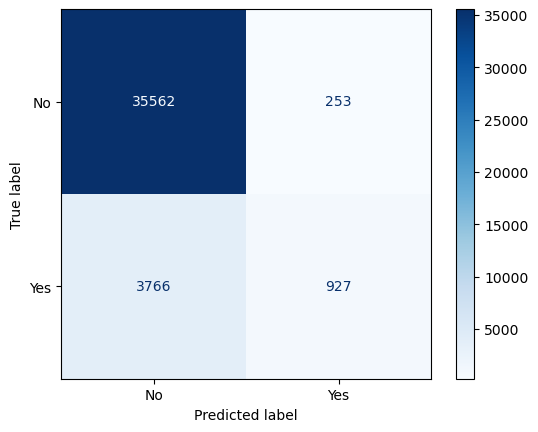

In [57]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Generate predictions for the training set
y_pred_rf = model_rf.predict(X_train_final)

# 2. Print the evaluation
print("--- RANDOM FOREST TRAINING EVALUATION ---")
print(classification_report(y_train, y_pred_rf))

# 3. Plot Confusion Matrix
cm_rf = confusion_matrix(y_train, y_pred_rf)
ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No', 'Yes']).plot(cmap='Blues')

              precision    recall  f1-score   support

           0       0.94      0.89      0.92     35815
           1       0.42      0.60      0.49      4693

    accuracy                           0.86     40508
   macro avg       0.68      0.74      0.70     40508
weighted avg       0.88      0.86      0.87     40508



<Figure size 800x600 with 0 Axes>

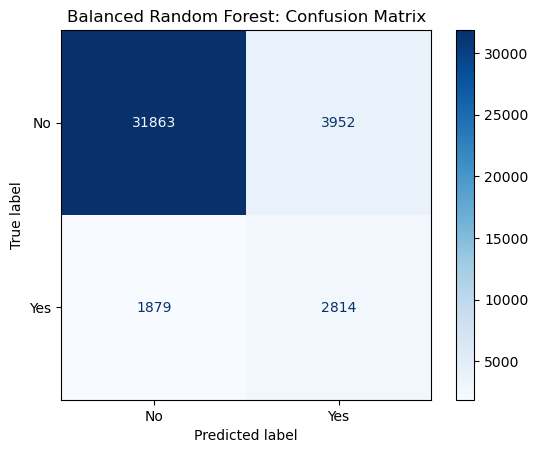

In [66]:
from sklearn.ensemble import RandomForestClassifier

# We increase depth to 10 and add 'class_weight'

model_rf_balanced = RandomForestClassifier(n_estimators=100, 
                                           max_depth=10, 
                                           class_weight='balanced', 
                                           random_state=42)

model_rf_balanced.fit(X_train_final, y_train)

# Re-evaluate
y_pred_new = model_rf_balanced.predict(X_train_final)
print(classification_report(y_train, y_pred_new))


from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Generate the Confusion Matrix numbers using the new balanced predictions
cm_balanced = confusion_matrix(y_train, y_pred_new)

# 2. Plot it
plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_balanced, display_labels=['No', 'Yes'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Balanced Random Forest: Confusion Matrix')
plt.show()

In [59]:
from sklearn.linear_model import LogisticRegression

# 1. Initialize the Model with 'balanced' weights
model_log = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)

# 2. Train the model
model_log.fit(X_train_final, y_train)

print("Logistic Regression Training Complete!")

Logistic Regression Training Complete!


--- LOGISTIC REGRESSION EVALUATION ---
              precision    recall  f1-score   support

           0       0.94      0.79      0.86     35815
           1       0.27      0.60      0.37      4693

    accuracy                           0.77     40508
   macro avg       0.60      0.69      0.61     40508
weighted avg       0.86      0.77      0.80     40508



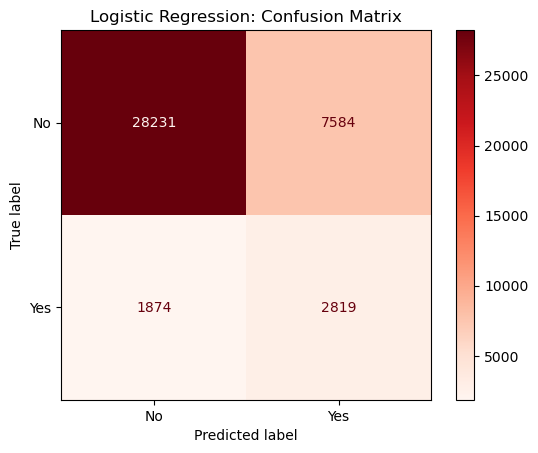

In [60]:
# 3. Generate predictions
y_pred_log = model_log.predict(X_train_final)

# 4. Print Report
print("--- LOGISTIC REGRESSION EVALUATION ---")
print(classification_report(y_train, y_pred_log))

# 5. Plot Confusion Matrix
cm_log = confusion_matrix(y_train, y_pred_log)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_log, display_labels=['No', 'Yes'])
disp.plot(cmap='Reds') # Using Red to distinguish from the RF Blue
plt.title('Logistic Regression: Confusion Matrix')
plt.show()

Both models managed to identify around 60% of the subscribers. However, the difference lies in how many false positivesthey produced to reach that point:
- Random Forest :3,952 false positives.
- Logistic Regression : 7,584 false positives.


- Random Forest Precision = 0.42 → For every 10 calls, ~4 people subscribe.
- Logistic Regression Precision = 0.27 → For every 10 calls, only ~2.7 people subscribe.
This shows Random Forest is more efficient, with fewer wasted calls


In [61]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# 1. Initialize the single tree
# We use the same random_state so the comparison is fair
dt_model = DecisionTreeClassifier(max_depth=10, random_state=42, class_weight='balanced')

# 2. Train the single tree
dt_model.fit(X_train_final, y_train)

# 3. Check the training performance
dt_train_acc = dt_model.score(X_train_final, y_train)

print(f"Decision Tree Training Completed!")
print(f"Decision Tree Training Accuracy: {dt_train_acc * 100:.2f}%")

Decision Tree Training Completed!
Decision Tree Training Accuracy: 85.02%


--- DECISION TREE EVALUATION ---
              precision    recall  f1-score   support

           0       0.94      0.89      0.91     35815
           1       0.40      0.57      0.47      4693

    accuracy                           0.85     40508
   macro avg       0.67      0.73      0.69     40508
weighted avg       0.88      0.85      0.86     40508



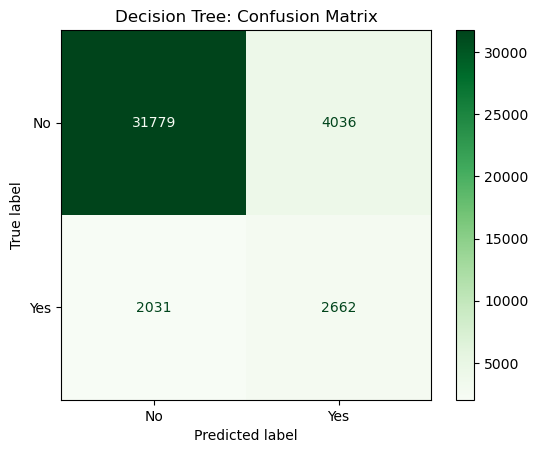

In [62]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Generate predictions using the Decision Tree model
y_pred_dt = dt_model.predict(X_train_final)

# 2. Print the Professional Report
print("--- DECISION TREE EVALUATION ---")
print(classification_report(y_train, y_pred_dt))

# 3. Plot Confusion Matrix
cm_dt = confusion_matrix(y_train, y_pred_dt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=['No', 'Yes'])

# Using Green to distinguish this from the other models
disp.plot(cmap='Greens') 
plt.title('Decision Tree: Confusion Matrix')
plt.show()

In [63]:
# 1. Separate the Target (y) from the Features (X) for Val and Test
y_val = validation['SubscribedProduct']
y_test = test['SubscribedProduct']

X_val = validation.drop(columns=['SubscribedProduct'])
X_test = test.drop(columns=['SubscribedProduct'])

# 2. Scale using the ALREADY TRAINED scaler (use .transform only!)
# This ensures Val and Test are scaled using the same logic as Train
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# 3. Convert to DataFrames so they look like X_train_final
X_val_final = pd.DataFrame(X_val_scaled, columns=X_val.columns)
X_test_final = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print("Validation and Test data are now scaled and ready!")

Validation and Test data are now scaled and ready!


--- VALIDATION PERFORMANCE COMPARISON ---

Model: Random Forest
F1-Score for Subscribers: 0.2816
              precision    recall  f1-score   support

           0       0.90      0.99      0.95      4000
           1       0.80      0.17      0.28       521

    accuracy                           0.90      4521
   macro avg       0.85      0.58      0.61      4521
weighted avg       0.89      0.90      0.87      4521



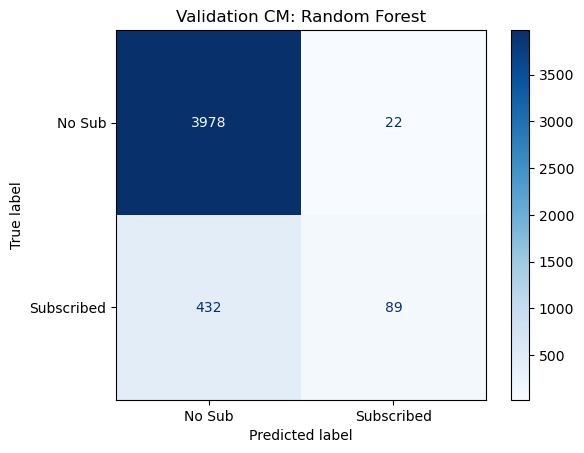

------------------------------

Model: Decision Tree
F1-Score for Subscribers: 0.4357
              precision    recall  f1-score   support

           0       0.93      0.89      0.91      4000
           1       0.38      0.51      0.44       521

    accuracy                           0.85      4521
   macro avg       0.66      0.70      0.67      4521
weighted avg       0.87      0.85      0.86      4521



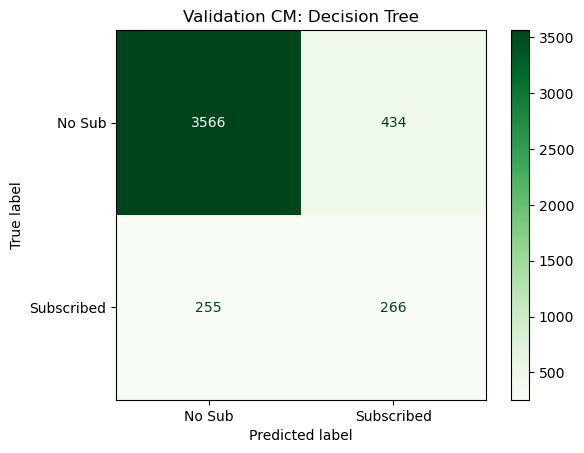

------------------------------

Model: Logistic Regression
F1-Score for Subscribers: 0.3483
              precision    recall  f1-score   support

           0       0.93      0.79      0.85      4000
           1       0.25      0.55      0.35       521

    accuracy                           0.76      4521
   macro avg       0.59      0.67      0.60      4521
weighted avg       0.85      0.76      0.80      4521



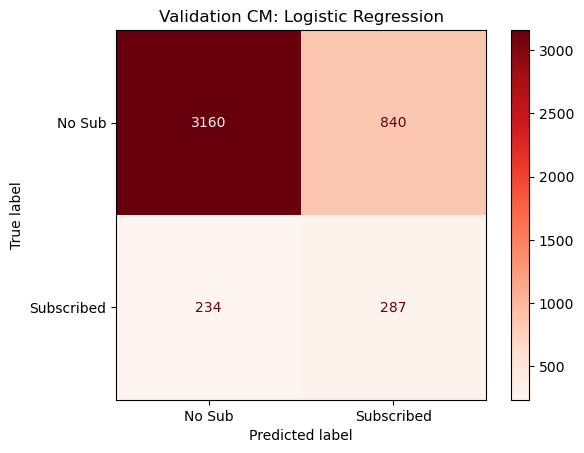

------------------------------


In [67]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
import matplotlib.pyplot as plt

# 1. Dictionary of our trained models
models = {
    "Random Forest": model_rf,
    "Decision Tree": dt_model,
    "Logistic Regression": model_log
}

# 2. Loop through and evaluate
print("--- VALIDATION PERFORMANCE COMPARISON ---")

for name, model in models.items():
    # Predict
    y_val_pred = model.predict(X_val_final)
    
    # Calculate F1 (The most important metric for imbalanced banking data)
    f1 = f1_score(y_val, y_val_pred)
    
    print(f"\nModel: {name}")
    print(f"F1-Score for Subscribers: {f1:.4f}")
    print(classification_report(y_val, y_val_pred))
    
    # Plot Confusion Matrix
    # Different colors: RF=Blues, DT=Greens, LogReg=Reds
    c_map = 'Blues' if "Forest" in name else 'Greens' if "Tree" in name else 'Reds'
    
    cm = confusion_matrix(y_val, y_val_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Sub', 'Subscribed'])
    disp.plot(cmap=c_map)
    plt.title(f"Validation CM: {name}")
    plt.show()
    print("-" * 30)

In [68]:
# We are going to over-correct the bias manually
# 0: 1 (Normal weight for 'No')
# 1: 12 (Huge weight for 'Yes' to force the model to find them)
custom_weights = {0: 1, 1: 12}

model_rf_heavy = RandomForestClassifier(
    n_estimators=200, 
    max_depth=12, 
    class_weight=custom_weights, 
    random_state=42
)

model_rf_heavy.fit(X_train_final, y_train)

RandomForestClassifier(class_weight={0: 1, 1: 12}, max_depth=12,
                       n_estimators=200, random_state=42)

--- VALIDATION PERFORMANCE COMPARISON ---

Model: Random Forest
F1-Score for Subscribers: 0.4204
              precision    recall  f1-score   support

           0       0.96      0.76      0.85      4000
           1       0.29      0.76      0.42       521

    accuracy                           0.76      4521
   macro avg       0.63      0.76      0.63      4521
weighted avg       0.88      0.76      0.80      4521



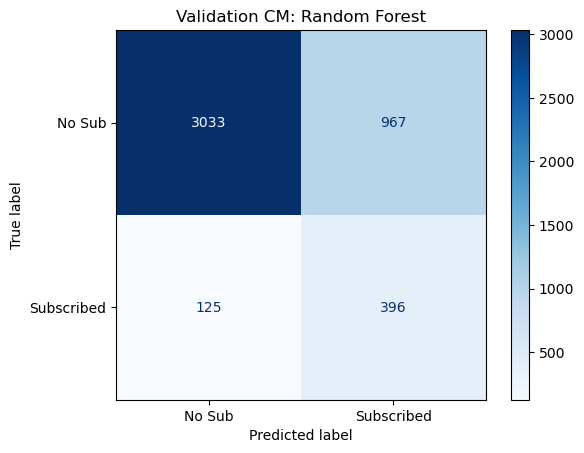

------------------------------

Model: Decision Tree
F1-Score for Subscribers: 0.4357
              precision    recall  f1-score   support

           0       0.93      0.89      0.91      4000
           1       0.38      0.51      0.44       521

    accuracy                           0.85      4521
   macro avg       0.66      0.70      0.67      4521
weighted avg       0.87      0.85      0.86      4521



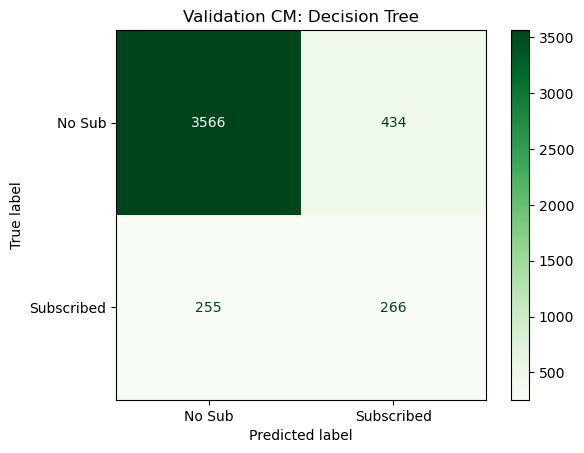

------------------------------

Model: Logistic Regression
F1-Score for Subscribers: 0.3483
              precision    recall  f1-score   support

           0       0.93      0.79      0.85      4000
           1       0.25      0.55      0.35       521

    accuracy                           0.76      4521
   macro avg       0.59      0.67      0.60      4521
weighted avg       0.85      0.76      0.80      4521



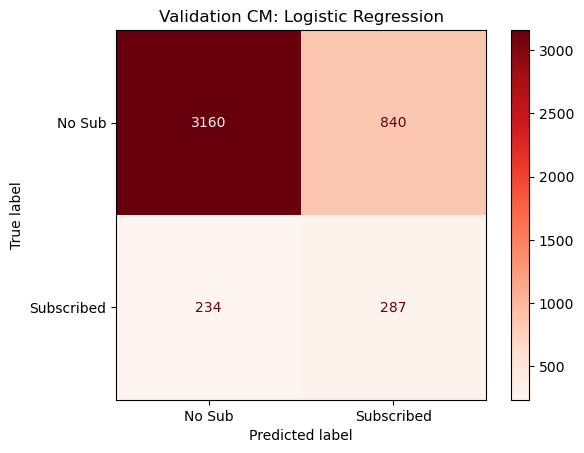

------------------------------


In [69]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
import matplotlib.pyplot as plt

# 1. Dictionary of our trained models
models = {
    "Random Forest": model_rf_heavy,
    "Decision Tree": dt_model,
    "Logistic Regression": model_log
}

# 2. Loop through and evaluate
print("--- VALIDATION PERFORMANCE COMPARISON ---")

for name, model in models.items():
    # Predict
    y_val_pred = model.predict(X_val_final)
    
    # Calculate F1 (The most important metric for imbalanced banking data)
    f1 = f1_score(y_val, y_val_pred)
    
    print(f"\nModel: {name}")
    print(f"F1-Score for Subscribers: {f1:.4f}")
    print(classification_report(y_val, y_val_pred))
    
    # Plot Confusion Matrix
    # Different colors: RF=Blues, DT=Greens, LogReg=Reds
    c_map = 'Blues' if "Forest" in name else 'Greens' if "Tree" in name else 'Reds'
    
    cm = confusion_matrix(y_val, y_val_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Sub', 'Subscribed'])
    disp.plot(cmap=c_map)
    plt.title(f"Validation CM: {name}")
    plt.show()
    print("-" * 30)

--- ROC-AUC SCORES (VALIDATION) ---
Random Forest: 0.8521
Decision Tree: 0.7595
Logistic Regression: 0.7239


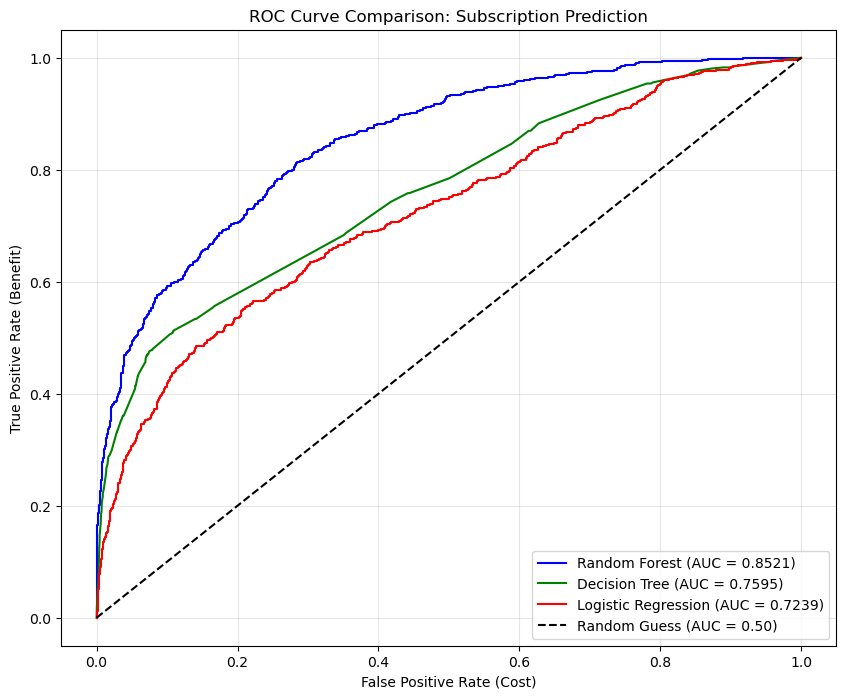

In [72]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# 1. Setup the plot
plt.figure(figsize=(10, 8))

# 2. Define the models to compare
# Using the probabilites (predict_proba) for the ROC curve
model_list = {
    "Random Forest": model_rf_heavy,
    "Decision Tree": dt_model,
    "Logistic Regression": model_log
}

colors = {'Random Forest': 'blue', 'Decision Tree': 'green', 'Logistic Regression': 'red'}

print("--- ROC-AUC SCORES (VALIDATION) ---")

for name, model in model_list.items():
    # Get probability for the '1' (Subscribed) class
    probs = model.predict_proba(X_val_final)[:, 1]
    
    # Calculate AUC
    auc = roc_auc_score(y_val, probs)
    print(f"{name}: {auc:.4f}")
    
    # Calculate ROC curve points
    fpr, tpr, thresholds = roc_curve(y_val, probs)
    
    # Plot the curve
    plt.plot(fpr, tpr, color=colors[name], label=f'{name} (AUC = {auc:.4f})')

# 3. Plot the "Random Guess" diagonal line
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.50)')

# 4. Final touches
plt.xlabel('False Positive Rate (Cost)')
plt.ylabel('True Positive Rate (Benefit)')
plt.title('ROC Curve Comparison: Subscription Prediction')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

--- FINAL TEST SET PERFORMANCE COMPARISON ---

Model: Random Forest (Tuned)
F1-Score for Subscribers: 0.3825
              precision    recall  f1-score   support

           0       0.95      0.74      0.83      4022
           1       0.26      0.69      0.38       540

    accuracy                           0.74      4562
   macro avg       0.61      0.72      0.61      4562
weighted avg       0.87      0.74      0.78      4562



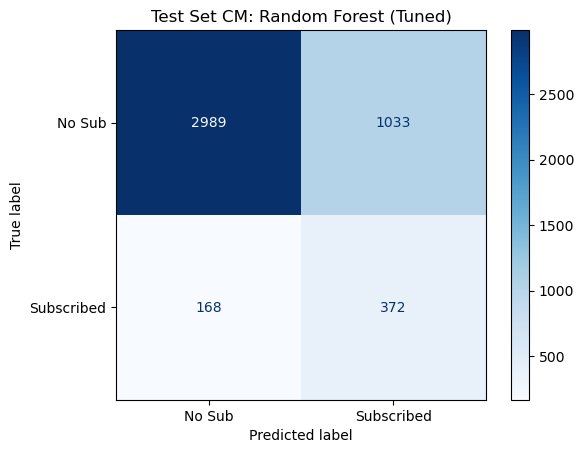

------------------------------

Model: Decision Tree
F1-Score for Subscribers: 0.4215
              precision    recall  f1-score   support

           0       0.93      0.89      0.91      4022
           1       0.37      0.49      0.42       540

    accuracy                           0.84      4562
   macro avg       0.65      0.69      0.66      4562
weighted avg       0.86      0.84      0.85      4562



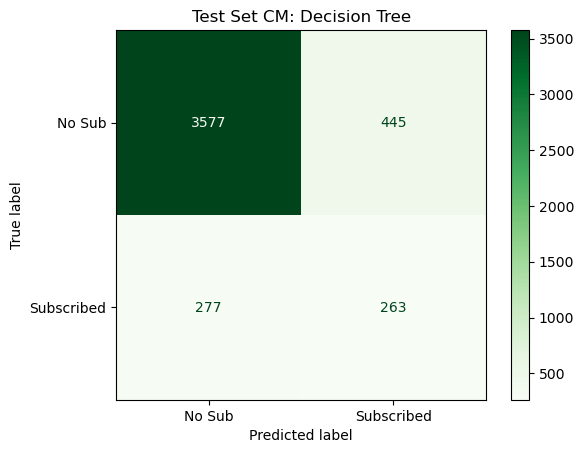

------------------------------

Model: Logistic Regression
F1-Score for Subscribers: 0.3760
              precision    recall  f1-score   support

           0       0.93      0.79      0.86      4022
           1       0.28      0.59      0.38       540

    accuracy                           0.77      4562
   macro avg       0.61      0.69      0.62      4562
weighted avg       0.86      0.77      0.80      4562



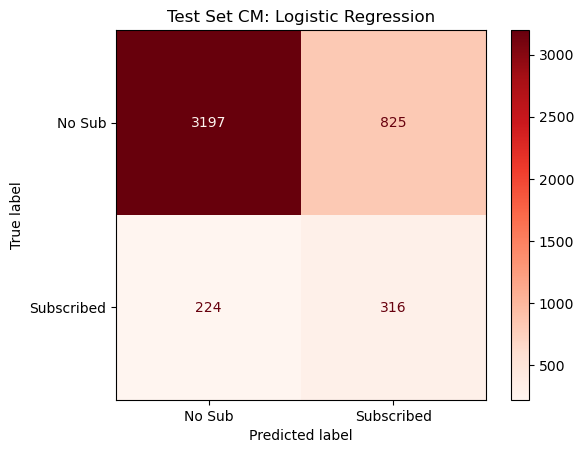

------------------------------


In [73]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
import matplotlib.pyplot as plt

# 1. Ensure you are using the optimized Random Forest
models = {
    "Random Forest (Tuned)": model_rf_heavy, # or model_rf_heavy, whichever holds your weighted version
    "Decision Tree": dt_model,
    "Logistic Regression": model_log
}

print("--- FINAL TEST SET PERFORMANCE COMPARISON ---")

for name, model in models.items():
    # Predict on TEST data
    y_test_pred = model.predict(X_test_final)
    
    # Calculate F1
    f1 = f1_score(y_test, y_test_pred)
    
    print(f"\nModel: {name}")
    print(f"F1-Score for Subscribers: {f1:.4f}")
    
    # Print Full Report (Precision, Recall, Support)
    print(classification_report(y_test, y_test_pred))
    
    # Plot Confusion Matrix
    c_map = 'Blues' if "Forest" in name else 'Greens' if "Tree" in name else 'Reds'
    
    cm = confusion_matrix(y_test, y_test_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Sub', 'Subscribed'])
    disp.plot(cmap=c_map)
    plt.title(f"Test Set CM: {name}")
    plt.show()
    print("-" * 30)

--- FINAL TEST SET ROC-AUC SCORES ---
Random Forest: 0.7871
Decision Tree: 0.7330
Logistic Regression: 0.7554


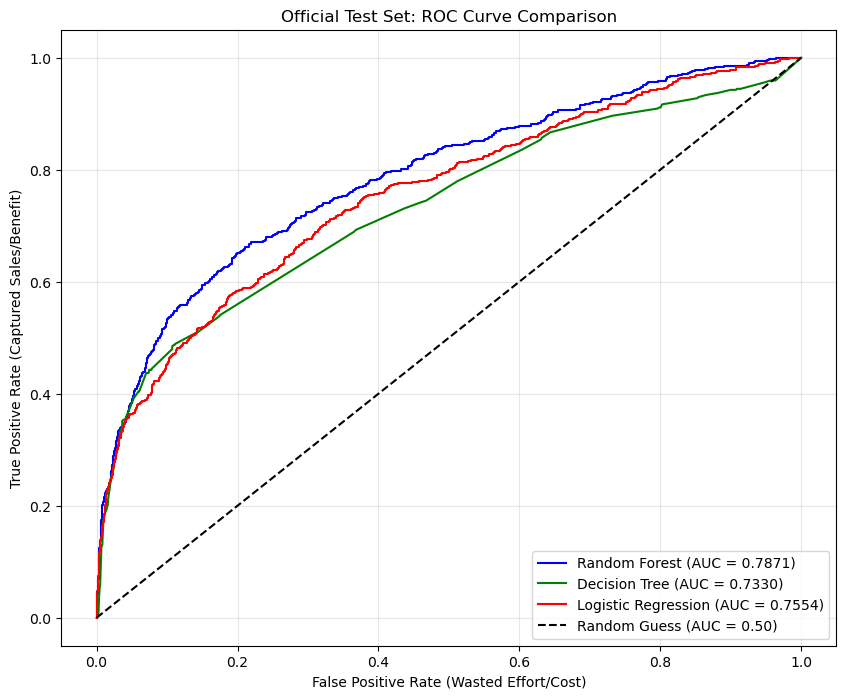

In [74]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# 1. Setup the plot
plt.figure(figsize=(10, 8))

# 2. Use your TEST data for the final evaluation
model_list = {
    "Random Forest": model_rf_heavy,
    "Decision Tree": dt_model,
    "Logistic Regression": model_log
}

colors = {'Random Forest': 'blue', 'Decision Tree': 'green', 'Logistic Regression': 'red'}

print("--- FINAL TEST SET ROC-AUC SCORES ---")

for name, model in model_list.items():
    # Get probability for the '1' class using TEST data
    probs = model.predict_proba(X_test_final)[:, 1]
    
    # Calculate AUC
    auc = roc_auc_score(y_test, probs)
    print(f"{name}: {auc:.4f}")
    
    # Calculate ROC curve points
    fpr, tpr, thresholds = roc_curve(y_test, probs)
    
    # Plot
    plt.plot(fpr, tpr, color=colors[name], label=f'{name} (AUC = {auc:.4f})')

# 3. Reference line
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.50)')

# 4. Labeling for your presentation
plt.xlabel('False Positive Rate (Wasted Effort/Cost)')
plt.ylabel('True Positive Rate (Captured Sales/Benefit)')
plt.title('Official Test Set: ROC Curve Comparison')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

--- FINAL EVALUATION SUMMARY ---
                 Model  Val_Accuracy  Test_Accuracy  Val_Recall  Test_Recall  \
0        Decision Tree          0.85           0.84        0.51         0.49   
1  Logistic Regression          0.76           0.77        0.55         0.59   
2        Random Forest          0.76           0.74        0.76         0.69   

   Val_F1  Test_F1  
0    0.44     0.42  
1    0.35     0.38  
2    0.42     0.38  


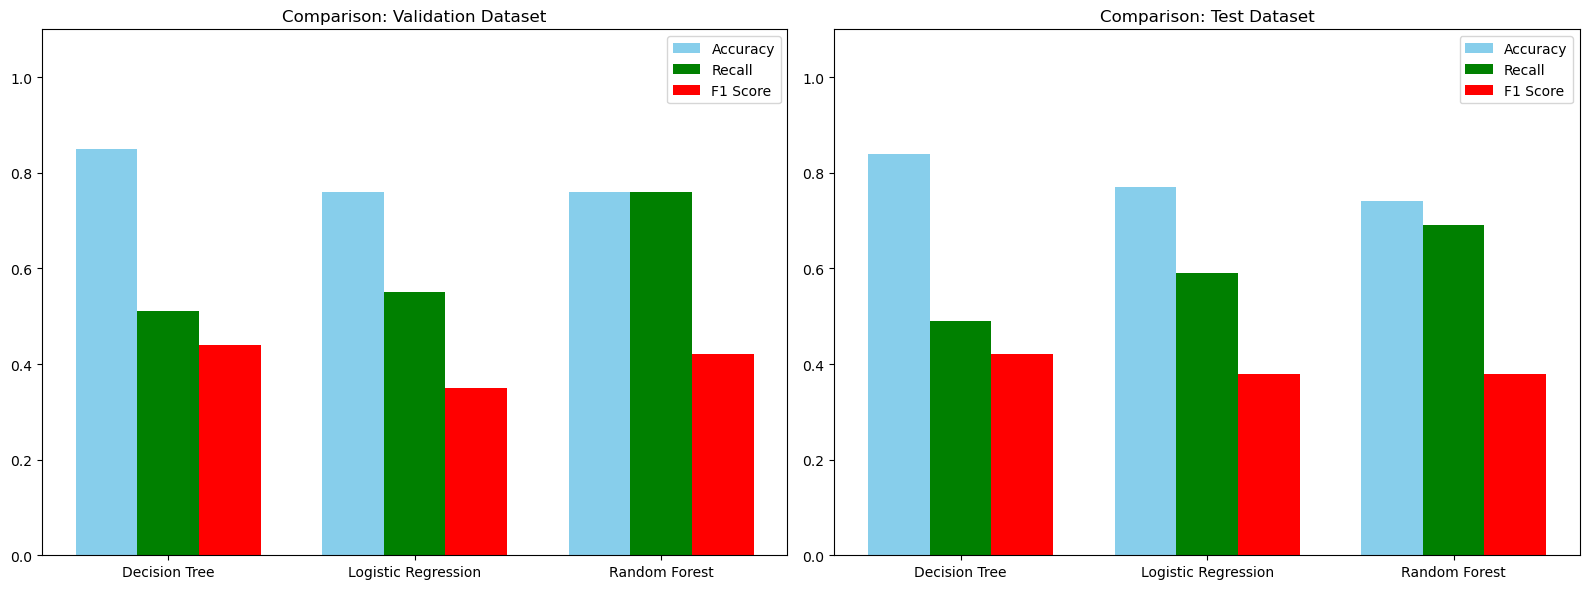

In [75]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Manually input your final results 
data = {
    'Model': ['Decision Tree', 'Logistic Regression', 'Random Forest'],
    'Val_Accuracy': [0.85, 0.76, 0.76],
    'Test_Accuracy': [0.84, 0.77, 0.74],
    'Val_Recall': [0.51, 0.55, 0.76],
    'Test_Recall': [0.49, 0.59, 0.69],
    'Val_F1': [0.44, 0.35, 0.42],
    'Test_F1': [0.42, 0.38, 0.38]
}

df = pd.DataFrame(data)

# 2. Display a Clean Table for your slides
print("--- FINAL EVALUATION SUMMARY ---")
print(df)

# 3. Create the Side-by-Side Bar Chart
metrics = ['Accuracy', 'Recall', 'F1 Score']
models = df['Model']

x = np.arange(len(models))  # Label locations
width = 0.25  # Width of the bars

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: Validation Results ---
ax1.bar(x - width, df['Val_Accuracy'], width, label='Accuracy', color='skyblue')
ax1.bar(x, df['Val_Recall'], width, label='Recall', color='green')
ax1.bar(x + width, df['Val_F1'], width, label='F1 Score', color='red')

ax1.set_title('Comparison: Validation Dataset')
ax1.set_xticks(x)
ax1.set_xticklabels(models)
ax1.legend()
ax1.set_ylim(0, 1.1)

# --- Plot 2: Test Results ---
ax2.bar(x - width, df['Test_Accuracy'], width, label='Accuracy', color='skyblue')
ax2.bar(x, df['Test_Recall'], width, label='Recall', color='green')
ax2.bar(x + width, df['Test_F1'], width, label='F1 Score', color='red')

ax2.set_title('Comparison: Test Dataset')
ax2.set_xticks(x)
ax2.set_xticklabels(models)
ax2.legend()
ax2.set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

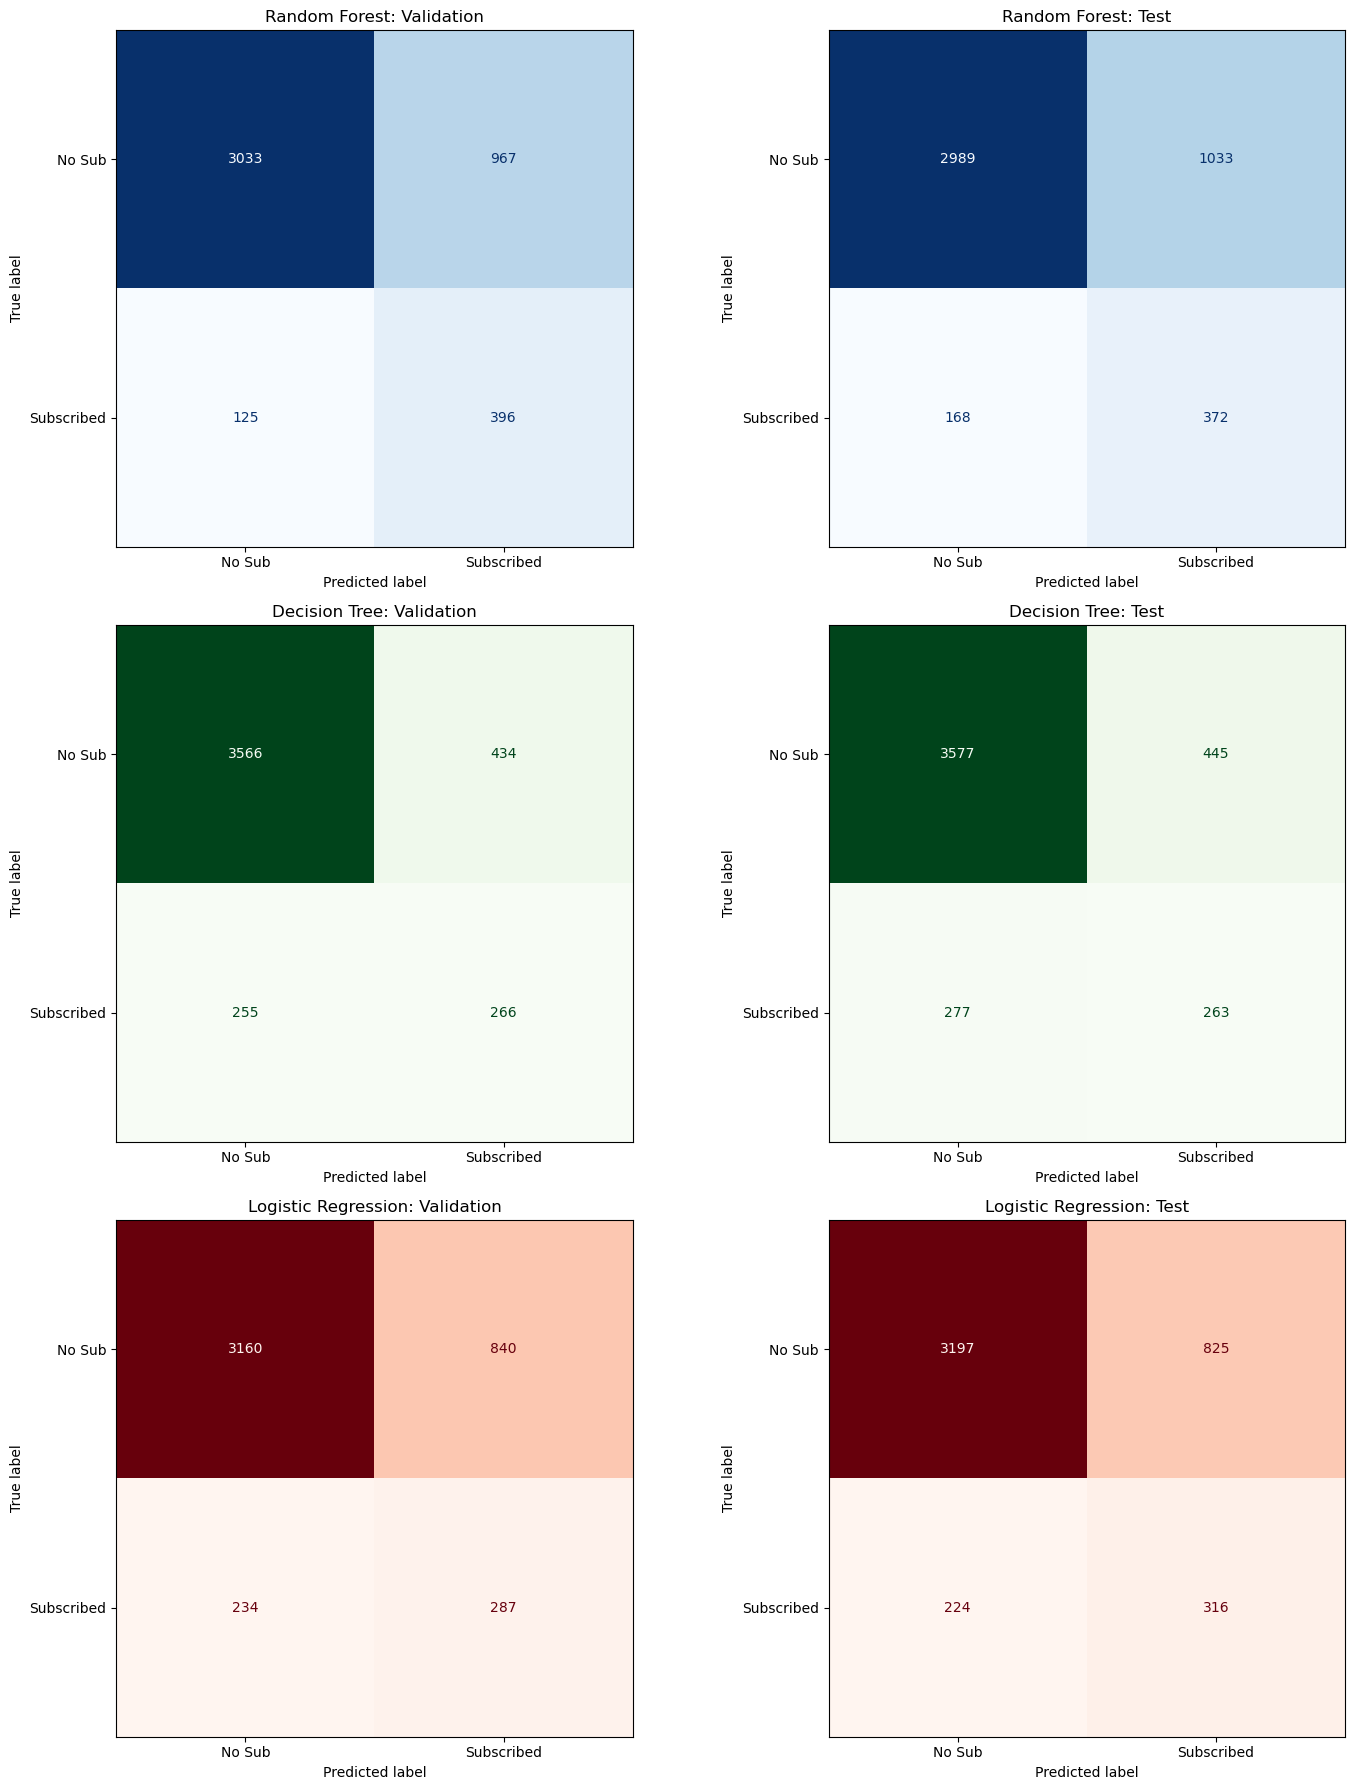

In [76]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# List of models and their names
models = [
    (model_rf_heavy, "Random Forest", "Blues"),
    (dt_model, "Decision Tree", "Greens"),
    (model_log, "Logistic Regression", "Reds")
]

# Create a 3x2 grid (Rows = Models, Columns = Val vs Test)
fig, axes = plt.subplots(3, 2, figsize=(15, 18))

for i, (model, name, cmap) in enumerate(models):
    # --- Column 1: Validation ---
    y_val_pred = model.predict(X_val_final)
    cm_val = confusion_matrix(y_val, y_val_pred)
    disp_val = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=['No Sub', 'Subscribed'])
    disp_val.plot(ax=axes[i, 0], cmap=cmap, colorbar=False)
    axes[i, 0].set_title(f"{name}: Validation")
    
    # --- Column 2: Test ---
    y_test_pred = model.predict(X_test_final)
    cm_test = confusion_matrix(y_test, y_test_pred)
    disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=['No Sub', 'Subscribed'])
    disp_test.plot(ax=axes[i, 1], cmap=cmap, colorbar=False)
    axes[i, 1].set_title(f"{name}: Test")

plt.tight_layout()
plt.show()

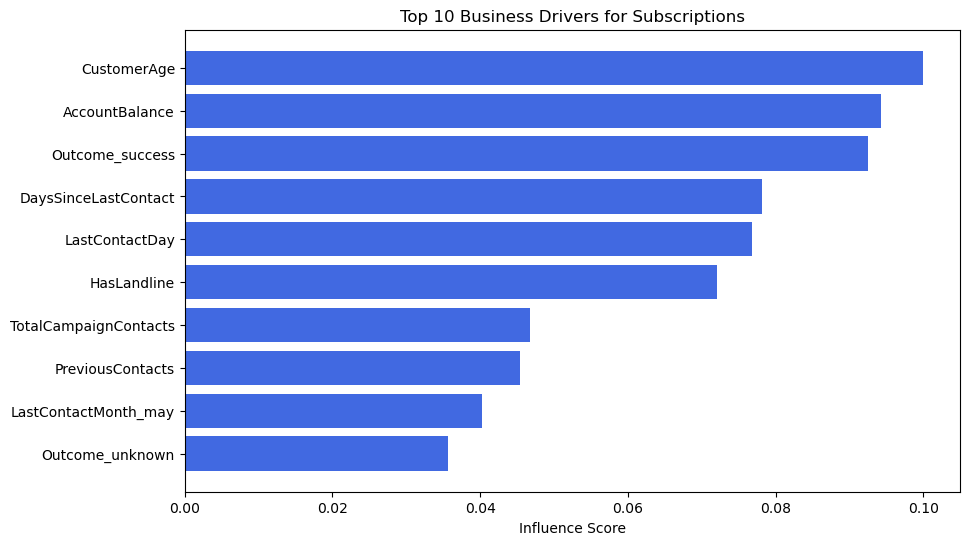

                  Feature  Importance
0             CustomerAge    0.099928
2          AccountBalance    0.094216
11        Outcome_success    0.092509
7    DaysSinceLastContact    0.078221
5          LastContactDay    0.076828
3             HasLandline    0.072000
6   TotalCampaignContacts    0.046804
8        PreviousContacts    0.045384
40   LastContactMonth_may    0.040266
12        Outcome_unknown    0.035614


In [77]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Get feature importance from your final Random Forest
importances = model_rf_heavy.feature_importances_
feature_names = X_train_final.columns # Use your feature names

# 2. Sort them
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# 3. Plot the Top 10 for the slide
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'].head(10), feature_importance_df['Importance'].head(10), color='royalblue')
plt.gca().invert_yaxis()
plt.title('Top 10 Business Drivers for Subscriptions')
plt.xlabel('Influence Score')
plt.show()

print(feature_importance_df.head(10))